# Task 2 - Final bagged model

This notebook combines the three tuned Task 2 classifiers into one final ensemble: a Decision Tree, a Random Forest, and a scaled MLP. The hyperparameters are the recorded best configurations from the corresponding random-search notebooks in this folder.

The ensemble uses soft voting: each model contributes its class probabilities, and the class with the largest mean probability is selected. All models are fitted only on the training partition, and the held-out validation partition is used once for final evaluation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20
SNR_LEVELS = ["SNR_noiseless", "SNR_50db", "SNR_40db", "SNR_30db", "SNR_20db"]
CLASS_NAMES = ["Normal", "Sag", "Swell", "Interruption", "Harmonics", "Sag_harmonics", "Swell_harmonics", "Transient", "Flicker"]
DISPLAY_CLASS_NAMES = ["Normal", "Sag", "Swell", "Interruption", "Harmonics", "Sag_harm", "Swell_harm", "Transient", "Flicker"]
NORMAL_LABEL = "Normal"
FEATURE_COLUMNS = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8"]
RAW_TO_FEATURE = {"avg abs": "F2", "sd": "F3", "max": "F4", "min": "F5", "no. pks": "F6", "sd fma": "F7", "sd fma 3": "F1", "no. pt near 0": "F8"}

def normal_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[NORMAL_LABEL], average="macro", zero_division=0)

## 1. Load the data and create a stratified train/validation split

The data loading and split match the random-search notebooks. Keeping the split fixed makes the final ensemble directly comparable with the three tuned component models.

In [2]:
def load_feature_data(data_root):
    frames = []
    for snr in SNR_LEVELS:
        snr_dir = data_root / snr
        if not snr_dir.is_dir():
            raise FileNotFoundError(f"Missing SNR directory: {snr_dir}")
        for csv_path in sorted(snr_dir.glob("*.csv")):
            label = csv_path.stem
            if label not in CLASS_NAMES:
                raise ValueError(f"Unexpected class file: {csv_path.name}")
            frame = pd.read_csv(csv_path).rename(columns=RAW_TO_FEATURE)
            missing = set(FEATURE_COLUMNS) - set(frame.columns)
            if missing:
                raise ValueError(f"{csv_path} is missing features: {sorted(missing)}")
            frame = frame[FEATURE_COLUMNS].copy()
            frame["label"] = label
            frame["snr"] = snr.removeprefix("SNR_")
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)

current = Path.cwd().resolve()
DATA_ROOT = next((path / "Code" / "data" for path in [current, *current.parents] if (path / "Code" / "data").is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError("Could not find Code/data. Run this notebook inside the project repository.")

dataset = load_feature_data(DATA_ROOT)
X = dataset[FEATURE_COLUMNS]
y = dataset["label"]
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"Using data from: {DATA_ROOT}")
print(f"Loaded {len(dataset):,} samples with {X.shape[1]} features.")
print(f"Training samples: {len(X_train):,}; validation samples: {len(X_valid):,}")

Using data from: /Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/05 Project/EE4C12---Machine-Learning-Project/Code/data
Loaded 6,705 samples with 8 features.
Training samples: 5,364; validation samples: 1,341


## 2. Fit the final soft-voting ensemble

The MLP is placed in a pipeline so that standardisation is learned from the training partition only. The tree-based models do not require scaling. Equal voting weights keep the ensemble contribution of the three independently tuned model families balanced.

In [3]:
decision_tree = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=3,
    criterion="gini",
    min_samples_split=6,
    random_state=RANDOM_STATE,
)

random_forest = RandomForestClassifier(
    n_estimators=316,
    max_depth=19,
    min_samples_leaf=1,
    criterion="log_loss",
    min_samples_split=18,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

mlp = Pipeline([
    ("scaler", StandardScaler()),
    (
        "mlp",
        MLPClassifier(
            solver="lbfgs",
            learning_rate_init=0.0003,
            hidden_layer_sizes=(32, 64, 32),
            alpha=0.01,
            activation="logistic",
            batch_size=64,
            max_iter=500,
            early_stopping=False,
            random_state=RANDOM_STATE,
        ),
    ),
])

final_model = VotingClassifier(
    estimators=[("decision_tree", decision_tree), ("random_forest", random_forest), ("mlp", mlp)],
    voting="soft",
)
final_model.fit(X_train, y_train)
print("Fitted component models:", ", ".join(name for name, _ in final_model.estimators))

Fitted component models: decision_tree, random_forest, mlp


/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


## 3. Evaluate the final ensemble

The metrics and class report use the same definitions as the individual model notebooks.

In [4]:
y_pred = final_model.predict(X_valid)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Normal precision", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"],
    "Value": [
        accuracy_score(y_valid, y_pred),
        normal_precision(y_valid, y_pred),
        precision_score(y_valid, y_pred, average="macro", zero_division=0),
        recall_score(y_valid, y_pred, average="macro", zero_division=0),
        f1_score(y_valid, y_pred, average="macro", zero_division=0),
        f1_score(y_valid, y_pred, average="weighted", zero_division=0),
    ],
})
display(metrics)

report = pd.DataFrame(
    classification_report(y_valid, y_pred, labels=CLASS_NAMES, output_dict=True, zero_division=0)
).T
display(report.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]])

,Metric,Value
0,Accuracy,0.984340
1,Normal precision,0.941176
2,Macro precision,0.984479
3,Macro recall,0.984340
4,Macro F1,0.984359
5,Weighted F1,0.984359


,precision,recall,f1-score,support
Normal,0.941176,0.966443,0.953642,149.0
Sag,1.000000,0.973154,0.986395,149.0
Swell,1.000000,1.000000,1.000000,149.0
Interruption,0.986755,1.000000,0.993333,149.0
Harmonics,0.993333,1.000000,0.996656,149.0
Sag_harmonics,0.993289,0.993289,0.993289,149.0
Swell_harmonics,1.000000,1.000000,1.000000,149.0
Transient,0.972789,0.959732,0.966216,149.0
Flicker,0.972973,0.966443,0.969697,149.0


## 4. Validation confusion matrix

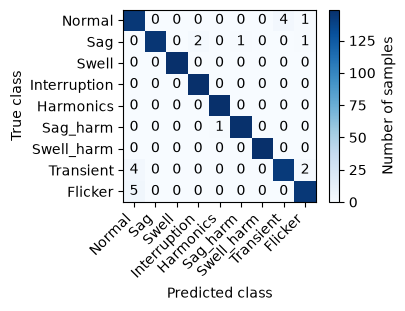

In [12]:
confusion = confusion_matrix(y_valid, y_pred, labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(3.5, 2.5))
image = ax.imshow(confusion, cmap="Blues")
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        if row != column:
            ax.text(column, row, confusion[row, column], ha="center", va="center")
ax.set_xticks(range(len(CLASS_NAMES)), DISPLAY_CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), DISPLAY_CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(image, ax=ax, label="Number of samples")

repository_root = next((path for path in [current, *current.parents] if (path / "Paper - IEEE").is_dir()), current)
output_path = repository_root / "Paper - IEEE" / "02_Plots" / "final_bagged_model_confusion_matrix.pdf"
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, bbox_inches="tight")
plt.show()

## 5. Robustness at each SNR level

This diagnostic evaluates the same fitted ensemble on each noise condition. It does not refit the component models.

In [6]:
validation_rows = dataset.loc[X_valid.index].copy()
validation_rows["prediction"] = y_pred

snr_metrics = []
for snr in SNR_LEVELS:
    mask = validation_rows["snr"].eq(snr.removeprefix("SNR_"))
    y_snr = validation_rows.loc[mask, "label"]
    pred_snr = validation_rows.loc[mask, "prediction"]
    snr_metrics.append({
        "SNR": snr.removeprefix("SNR_"),
        "Samples": len(y_snr),
        "Accuracy": accuracy_score(y_snr, pred_snr),
        "Macro F1": f1_score(y_snr, pred_snr, average="macro", zero_division=0),
        "Normal precision": normal_precision(y_snr, pred_snr),
    })

display(pd.DataFrame(snr_metrics))

,SNR,Samples,Accuracy,Macro F1,Normal precision
0,noiseless,267,0.996255,0.996353,0.966667
1,50db,249,1.000000,1.000000,1.000000
2,40db,271,1.000000,1.000000,1.000000
3,30db,284,0.978873,0.979764,0.894737
4,20db,270,0.948148,0.947992,0.866667


## Interpretation

Use the ensemble metrics, class report, confusion matrix, and SNR table to compare the final soft-voting model with the individual tuned Decision Tree, Random Forest, and MLP models.